# 03 · The modelling dataset: a summary

**Goal:** check and describe `data/processed/va_model_data.parquet`, the table the frequency and severity models (weeks 3–5) will use. It's built by `src/build_dataset.py`, and every rule is explained in `docs/modeling_dataset.md`.

**One row = one rating cell in one year:** a group of Virginia policies that share the same county, flood-zone group, occupancy group, floors, elevated / primary-residence / post-FIRM flags, construction-year band, and building-coverage band. Each row holds:

| Column | Plain English |
|---|---|
| `exposure` | earned policy-years in force in that cell (one home insured for a full year = 1) |
| `claims` | paid claims (total paid > $0): the **frequency** target |
| `losses_2025` | total paid, restated in **2025 dollars** with CPI-U: the **severity / pure-premium** target |

Years 2010–2025. All dollars in this notebook are 2025 dollars unless they're labeled nominal.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import build_dataset as bd   # our own module: src/build_dataset.py

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# --- Chart style: the same quiet look as notebook 01 ------------------------
BLUE = "#2a78d6"     # main data colour
ORANGE = "#eb6834"   # highlight colour (estimates / call-outs)
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "hatch.color": SURFACE, "hatch.linewidth": 1.2,
})

def save(fig, name):
    # Save a chart to reports/figures/ and show where it went
    path = FIG / f"03_{name}.png"
    fig.savefig(path)
    print(f"saved {path.relative_to(ROOT)}")

def thousands(x, pos=None):
    return f"{x:,.0f}"

def dollars_short(x, pos=None):
    # $500, $10K, $2.5M: short dollar labels so axis ticks don't collide
    if abs(x) >= 1e6:
        return f"${x / 1e6:,.0f}M" if x % 1e6 == 0 else f"${x / 1e6:,.1f}M"
    if abs(x) >= 1e4 or (abs(x) >= 1e3 and x % 1e3 == 0):
        return f"${x / 1e3:,.0f}K"
    if abs(x) >= 1e3:
        return f"${x / 1e3:,.1f}K"
    return f"${x:,.0f}"

def fmt_money(x):
    return f"${x:,.0f}"

## 1. Load the table and re-check the totals
The build script already checks all of this every time it runs. We repeat the headline totals here so the notebook stands on its own. They must match notebook 02 exactly, because the cells only re-slice the same exposure and claims.

In [2]:
cells = pd.read_parquet(bd.OUT_FILE)
checks = json.loads(bd.CHECKS_FILE.read_text(encoding="utf-8"))
matched = cells[cells.exposure_matched]            # rows with exposure (used for frequency)

tot = cells[["exposure", "claims_all", "claims", "losses_nominal", "losses_2025"]].sum()
for k, ref in bd.REFERENCE_TOTALS.items():
    assert abs(tot[k] - ref) < 0.01, (k, tot[k], ref)

freq = matched.claims.sum() / matched.exposure.sum()
sev = cells.losses_2025.sum() / cells.claims.sum()
print(f"Rating cells (rows):        {len(cells):,}")
print(f"  with exposure:            {len(matched):,}")
print(f"  claims but no exposure:   {(~cells.exposure_matched).sum():,}  (see section 5)")
print(f"Feature combinations (ignoring year): {len(cells.drop_duplicates(['county', *bd.CELL_FEATURES])):,}")
print()
print(f"Exposure:         {tot.exposure:>14,.2f} policy-years   (notebook 02: {bd.REFERENCE_TOTALS['exposure']:,.2f})")
print(f"Paid claims:      {tot.claims:>14,.0f}                (notebook 02: {bd.REFERENCE_TOTALS['claims']:,})")
print(f"Losses, nominal: ${tot.losses_nominal:>14,.0f}                (notebook 02: ${bd.REFERENCE_TOTALS['losses_nominal']:,.0f})")
print(f"Losses, 2025 $:  ${tot.losses_2025:>14,.0f}  (+{tot.losses_2025 / tot.losses_nominal - 1:.0%} after inflation)")
print()
print(f"Frequency:    {freq * 1000:.2f} paid claims per 1,000 policy-years (cells with exposure)")
print(f"Severity:     ${sev:,.0f} per paid claim (2025 $; nominal was ${tot.losses_nominal / tot.claims:,.0f})")
print(f"Pure premium: ${tot.losses_2025 / tot.exposure:,.0f} per policy-year (2025 $; nominal was ${tot.losses_nominal / tot.exposure:,.0f})")

Rating cells (rows):        252,531
  with exposure:            252,420
  claims but no exposure:   111  (see section 5)
Feature combinations (ignoring year): 29,087

Exposure:           1,482,412.77 policy-years   (notebook 02: 1,482,412.77)
Paid claims:               9,557                (notebook 02: 9,557)
Losses, nominal: $   220,183,315                (notebook 02: $220,183,315)
Losses, 2025 $:  $   292,685,981  (+33% after inflation)

Frequency:    6.38 paid claims per 1,000 policy-years (cells with exposure)
Severity:     $30,625 per paid claim (2025 $; nominal was $23,039)
Pure premium: $197 per policy-year (2025 $; nominal was $149)


**Reading this:** inflation adjustment raises the average paid claim from about \$23K to about \$31K, and the loss cost from about \$149 to about \$197 per policy-year. That's because a 2011 dollar bought about 43% more than a 2025 dollar. Without the adjustment, a model would mistake general price rises for rising flood risk.

## 2. How is exposure spread across cells?
Splitting 1.48 million policy-years over many feature combinations gives a lot of small cells. Most cells are a single building-type in a single county and year.

In [3]:
e = matched.exposure
q = e.quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.99])
print("Exposure per cell (policy-years):")
print(q.rename(lambda p: f"  {p:.0%} of cells have at most").round(2).to_string())
print(f"  largest cell: {e.max():,.0f}")
print()
print(f"Cells with less than 1 policy-year:   {(e < 1).mean():.0%}")
print(f"Cells with 10+ policy-years:          {(e >= 10).mean():.0%}, holding {e[e >= 10].sum() / e.sum():.0%} of all exposure")
top = e.sort_values(ascending=False)
print(f"The biggest 10% of cells hold {top.iloc[: len(top) // 10].sum() / e.sum():.0%} of exposure")

Exposure per cell (policy-years):
10% of cells have at most     0.61
25% of cells have at most     1.00
50% of cells have at most     1.00
75% of cells have at most     3.00
90% of cells have at most     9.46
99% of cells have at most    86.99
  largest cell: 1,552

Cells with less than 1 policy-year:   18%
Cells with 10+ policy-years:          10%, holding 70% of all exposure
The biggest 10% of cells hold 71% of exposure


saved reports\figures\03_cell_exposure.png


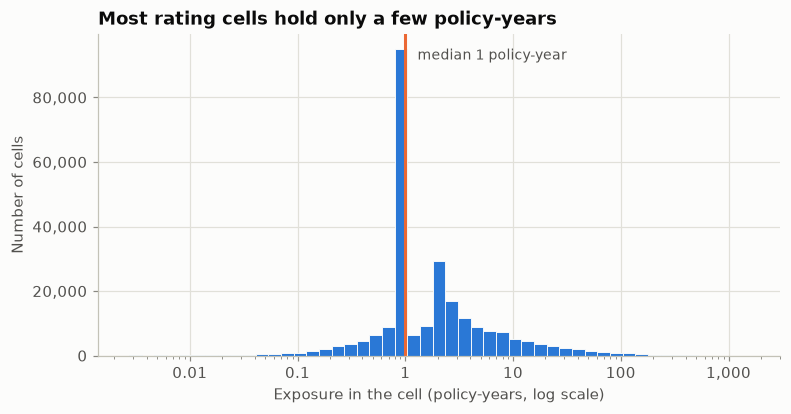

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.logspace(np.log10(e.min()), np.log10(e.max()), 50)
ax.hist(e, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f"{x:,.0f}" if x >= 1 else f"{x:g}"))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
ax.axvline(e.median(), color=ORANGE, linewidth=2)
ax.annotate(f"median {e.median():.0f} policy-year", (e.median(), ax.get_ylim()[1] * 0.92),
            xytext=(8, 0), textcoords="offset points", color=INK_2, fontsize=9)
ax.set_title("Most rating cells hold only a few policy-years")
ax.set_xlabel("Exposure in the cell (policy-years, log scale)")
ax.set_ylabel("Number of cells")
save(fig, "cell_exposure")
plt.show()

## 3. Why do most cells have zero claims?
A **Poisson** distribution describes counts of rare, independent events. If a cell's expected number of claims is λ ("lambda"), the chance of seeing **zero** claims is $e^{-\lambda}$.

*Example:* Virginia's paid-claim frequency is about 6.5 per 1,000 policy-years. A cell with 1 policy-year expects λ = 1 × 0.0065 = 0.0065 claims, so P(0 claims) = $e^{-0.0065}$ ≈ **99.4%**. Even a cell with 100 policy-years expects only 0.65 claims, so P(0) ≈ 52%. **Zeros are the normal outcome for small cells, not missing data.**

Below we compare the actual share of zero-claim cells with what Poisson predicts if every cell had that **year's** statewide frequency (so storm years are allowed for).

In [5]:
year_rate = matched.groupby("year").claims.sum() / matched.groupby("year").exposure.sum()
lam = matched.exposure * matched.year.map(year_rate)             # expected claims per cell
size_band = pd.cut(matched.exposure, [0, 1, 3, 10, 30, 100, np.inf],
                   labels=["<1", "1-3", "3-10", "10-30", "30-100", "100+"], right=False)
zero = (pd.DataFrame({"band": size_band, "actual_zero": matched.claims == 0,
                      "poisson_zero": np.exp(-lam), "exposure": matched.exposure})
          .groupby("band", observed=True)
          .agg(cells=("actual_zero", "size"), exposure=("exposure", "sum"),
               actual_zero_share=("actual_zero", "mean"), poisson_zero_share=("poisson_zero", "mean")))
print(f"All cells with exposure: {(matched.claims == 0).mean():.1%} have zero paid claims "
      f"(Poisson with yearly statewide rates expects {np.exp(-lam).mean():.1%})")
zero.style.format({"cells": "{:,}", "exposure": "{:,.0f}", "actual_zero_share": "{:.1%}", "poisson_zero_share": "{:.1%}"})

All cells with exposure: 98.0% have zero paid claims (Poisson with yearly statewide rates expects 97.3%)


,cells,exposure,actual_zero_share,poisson_zero_share
band,,,,
<1,"45,411","24,797",99.6%,99.6%
1-3,"136,620","186,763",99.1%,99.1%
3-10,"46,192","232,441",97.5%,96.9%
10-30,"15,346","257,793",93.5%,90.6%
30-100,"6,742","351,056",86.4%,77.2%
100+,"2,109","429,562",77.5%,52.8%


saved reports\figures\03_zero_claim_cells.png


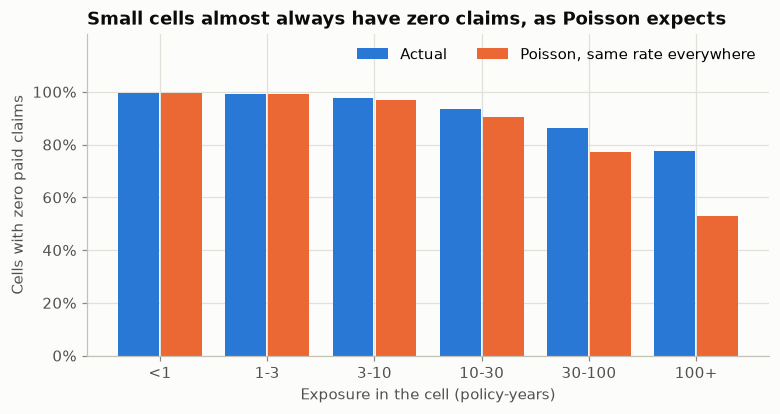

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(zero))
w = 0.38
ax.bar(x - w / 2 - 0.01, zero.actual_zero_share * 100, w, color=BLUE, label="Actual")
ax.bar(x + w / 2 + 0.01, zero.poisson_zero_share * 100, w, color=ORANGE, label="Poisson, same rate everywhere")
ax.set_xticks(x, zero.index)
ax.set_ylim(0, 122)
ax.set_yticks(range(0, 101, 20))
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_xlabel("Exposure in the cell (policy-years)")
ax.set_ylabel("Cells with zero paid claims")
ax.set_title("Small cells almost always have zero claims, as Poisson expects")
ax.legend(frameon=False, loc="upper right", ncol=2)
save(fig, "zero_claim_cells")
plt.show()

**Why the Poisson GLM handles all these zeros fine:** the model is fitted by **maximum likelihood**, meaning it picks the rates that make the observed counts most probable. A zero in a cell with λ = 0.006 is very probable, so it barely moves the estimates. A zero in a big cell (λ = 5) is surprising and pushes that cell's rate down. The **offset** log(exposure) tells the model how much exposure each cell has, so small and big cells are weighted correctly. Throwing away zero rows would be a serious mistake: it would keep only the "lucky" cells that had claims, and frequency would be grossly overstated.

Where actual and Poisson differ, it's because cells **aren't all the same risk** (that's what the features are for) and because storms make claims cluster (**overdispersion**, seen in notebook 02). In big cells we see *more* zeros than the flat-rate Poisson predicts. Claims concentrate in particular cells (high-risk zones, storm-hit counties), which leaves the rest quieter than average. That's the signal the model will look for.

## 4. A first look by feature
For each feature: its share of exposure, paid-claim **frequency** (per 1,000 policy-years), **severity** (average paid claim, 2025 $), and **pure premium** (2025 $ per policy-year). These are *one-way* views: each looks at one feature alone. Features overlap (for example, elevated buildings are mostly in A/V zones), so the GLM in week 3 will separate their effects.

Frequency uses cells with exposure. Severity uses every paid claim (including the 95 unmatched ones).

In [7]:
def one_way(feature):
    m = matched.groupby(feature).agg(exposure=("exposure", "sum"), claims_m=("claims", "sum"),
                                     losses_m=("losses_2025", "sum"))
    a = cells.groupby(feature).agg(claims=("claims", "sum"), losses=("losses_2025", "sum"))
    t = m.join(a)
    t["exposure share"] = t.exposure / t.exposure.sum()
    t["frequency per 1,000"] = t.claims_m / t.exposure * 1000
    t["severity (2025 $)"] = t.losses / t.claims
    t["pure premium (2025 $)"] = t.losses_m / t.exposure
    t["paid claims"] = t.claims
    return t[["exposure", "exposure share", "paid claims", "frequency per 1,000",
              "severity (2025 $)", "pure premium (2025 $)"]]

FMT = {"exposure": "{:,.0f}", "exposure share": "{:.1%}", "paid claims": "{:,.0f}",
       "frequency per 1,000": "{:.2f}", "severity (2025 $)": "${:,.0f}", "pure premium (2025 $)": "${:,.0f}"}
summary = {f: one_way(f) for f in ["coastal", *bd.CELL_FEATURES]}
for f, t in summary.items():
    display(t.style.format(FMT).set_caption(f"<b>{f}</b>"))

,exposure,exposure share,paid claims,"frequency per 1,000",severity (2025 $),pure premium (2025 $)
coastal,,,,,,
False,"385,288",26.0%,"2,560",6.47,"$31,251",$203
True,"1,097,125",74.0%,"6,997",6.35,"$30,396",$192


,exposure,exposure share,paid claims,"frequency per 1,000",severity (2025 $),pure premium (2025 $)
flood_zone_group,,,,,,
A/V high risk,"756,383",51.0%,"6,856",8.99,"$32,637",$292
B/C/X moderate-low risk,"726,030",49.0%,"2,701",3.67,"$25,519",$94


,exposure,exposure share,paid claims,"frequency per 1,000",severity (2025 $),pure premium (2025 $)
occupancy_group,,,,,,
multi-unit residential,"89,693",6.1%,799,8.84,"$58,864",$519
non-residential,"69,445",4.7%,492,6.88,"$77,799",$535
single-unit residential,"1,323,275",89.3%,"8,266",6.19,"$25,088",$155


,exposure,exposure share,paid claims,"frequency per 1,000",severity (2025 $),pure premium (2025 $)
floors_group,,,,,,
1,"483,798",32.6%,"3,032",6.17,"$36,033",$222
2,"748,353",50.5%,"4,755",6.31,"$29,617",$186
3+,"250,262",16.9%,"1,770",7.00,"$24,069",$169


,exposure,exposure share,paid claims,"frequency per 1,000",severity (2025 $),pure premium (2025 $)
elevated,,,,,,
False,"869,670",58.7%,"5,437",6.19,"$38,290",$237
True,"612,743",41.3%,"4,120",6.66,"$20,511",$136


,exposure,exposure share,paid claims,"frequency per 1,000",severity (2025 $),pure premium (2025 $)
primary_residence,,,,,,
False,"411,896",27.8%,"2,909",6.95,"$43,188",$300
True,"1,070,517",72.2%,"6,648",6.16,"$25,128",$155


,exposure,exposure share,paid claims,"frequency per 1,000",severity (2025 $),pure premium (2025 $)
post_firm,,,,,,
False,"756,195",51.0%,"7,143",9.34,"$31,761",$297
True,"726,218",49.0%,"2,414",3.30,"$27,266",$89


,exposure,exposure share,paid claims,"frequency per 1,000",severity (2025 $),pure premium (2025 $)
construction_band,,,,,,
1960-1979,"429,157",28.9%,"4,213",9.70,"$38,682",$376
1980-1999,"457,117",30.8%,"1,568",3.40,"$26,989",$91
2000 or later,"283,113",19.1%,580,2.02,"$22,930",$46
before 1960,"313,026",21.1%,"3,196",10.13,"$23,186",$235


,exposure,exposure share,paid claims,"frequency per 1,000",severity (2025 $),pure premium (2025 $)
building_coverage_band,,,,,,
$0 (contents only),"20,110",1.4%,199,9.80,"$16,077",$143
$100K-$249K,"421,149",28.4%,"3,676",8.64,"$29,264",$252
$250K or more,"901,092",60.8%,"4,388",4.83,"$35,515",$172
under $100K,"140,062",9.4%,"1,294",9.10,"$20,147",$180


In [8]:
# By year (frequency and pure premium swing with storms; severity in 2025 $ is steadier)
by_year = one_way("year")
by_year.style.format(FMT)

,exposure,exposure share,paid claims,"frequency per 1,000",severity (2025 $),pure premium (2025 $)
year,,,,,,
2010,"97,308",6.6%,245,2.45,"$15,410",$35
2011,"99,041",6.7%,"2,795",28.07,"$21,577",$603
2012,"101,788",6.9%,"1,197",11.72,"$28,871",$338
2013,"103,184",7.0%,230,2.18,"$21,516",$47
2014,"100,509",6.8%,305,2.99,"$30,667",$91
2015,"96,867",6.5%,358,3.62,"$19,396",$71
2016,"92,510",6.2%,"2,343",25.22,"$44,467","$1,119"
2017,"92,082",6.2%,82,0.87,"$25,526",$22
2018,"94,256",6.4%,615,6.37,"$36,446",$233


In [9]:
# By county group: the 32 counties with >= 5,000 policy-years, plus 3 pooled groups.
cg = one_way("county_group")
names = cells.drop_duplicates("county_group").set_index("county_group").county_name
cg.index = [f"{i} {names[i]}" if i[0].isdigit() else i for i in cg.index]
cg.sort_values("pure premium (2025 $)", ascending=False).style.format(FMT)

,exposure,exposure share,paid claims,"frequency per 1,000",severity (2025 $),pure premium (2025 $)
51700 Newport News city,"34,288",2.3%,339,9.83,"$59,860",$591
51775 Salem city,"6,485",0.4%,83,12.64,"$45,861",$584
51161 Roanoke County,"6,711",0.5%,101,14.60,"$26,227",$386
51770 Roanoke city,"8,619",0.6%,125,14.04,"$26,362",$375
Other inland (small),"140,592",9.5%,"1,199",8.17,"$37,627",$310
51810 Virginia Beach city,"298,421",20.1%,"2,072",6.94,"$43,049",$299
51510 Alexandria city,"18,415",1.2%,171,9.12,"$30,917",$280
51800 Suffolk city,"15,328",1.0%,78,4.57,"$52,737",$226
51740 Portsmouth city,"55,140",3.7%,425,7.67,"$27,979",$211
51710 Norfolk city,"154,653",10.4%,"1,333",8.61,"$22,462",$192


## 5. Claims that couldn't be matched to exposure
Every claim is placed in a cell using its own features. For 122 claims (95 paid), no policy with that exact combination of county, year, and features was in force, so the cell has exposure = 0. They're kept (flag `exposure_matched = False`) so totals reconcile. Frequency models will drop them, and severity models can use them.

In [10]:
u = checks["unmatched"]
print(f"Unmatched: {u['cells']} cells, {u['claims_all']} claims ({u['claims']} paid = {u['share_of_paid_claims']:.2%} of paid claims), "
      f"${u['losses_nominal']:,.0f} nominal = {u['share_of_losses']:.2%} of losses")
display(pd.DataFrame(u["by_reason"]))
print("How many unmatched claims would match if this ONE feature were ignored (a claim can count under several):")
display(pd.DataFrame(u["by_feature"]))

Unmatched: 111 cells, 122 claims (95 paid = 0.99% of paid claims), $2,698,593 nominal = 1.23% of losses


,reason,cells,claims_all,claims,losses_nominal
0,b. differs from all in-force policies on exact...,1,2,2,47545.19
1,c. would match if any one of several features ...,110,120,93,2651047.63


How many unmatched claims would match if this ONE feature were ignored (a claim can count under several):


,feature_ignored,claims_all_that_would_match,only_fix_for_claims_all
0,county,118,2
1,building_coverage_band,105,0
2,floors_group,52,0
3,construction_band,48,0
4,flood_zone_group,44,0
5,elevated,35,0
6,primary_residence,28,0
7,occupancy_group,21,0
8,post_firm,7,0


## 6. Takeaways
1. **The table is complete.** 252,531 rating cells hold exactly notebook 02's exposure (1,482,412.77 policy-years), claims (9,557 paid), and losses (\$220.2M nominal = **\$292.7M in 2025 dollars**). In 2025 dollars, Virginia's loss cost is about **\$197 per policy-year**: 6.4 paid claims per 1,000 policy-years × \$30,625 per paid claim.
2. **Cells are small and mostly claim-free, and that's expected.** The median cell has 1 policy-year, and 98% of cells have no paid claim. Poisson with each year's statewide rate predicts 97% zeros, almost the same. The Poisson GLM uses every zero through the exposure offset, so none should be dropped. The biggest 10% of cells hold 71% of the exposure.
3. **Big cells have more zeros than a flat rate predicts** (77% vs 53% for cells with 100+ policy-years). Risk isn't spread evenly: claims cluster in particular kinds of cells. That's exactly the variation the features should explain (and part of the overdispersion seen in notebook 02).
4. **The one-way views already show strong, sensible signals** (pure premium in 2025 \$ per policy-year):
   - **Flood zone:** A/V \$292 vs B/C/X \$94 (frequency 9.0 vs 3.7 per 1,000).
   - **Pre-FIRM** (built before flood maps) \$297 vs post-FIRM \$89. By year built: before 1960 \$235, 1960–79 \$376, 1980–99 \$91, 2000+ \$46.
   - **Second homes and rentals** (not primary residence) \$300 vs \$155. They're more often near the water.
   - **Elevated buildings** have slightly *more* claims (6.7 vs 6.2 per 1,000) but claims about **half the size** (\$20.5K vs \$38.3K), so a lower pure premium (\$136 vs \$237). Damage is often limited to the area below the raised floor.
   - **Multi-unit and non-residential** buildings have far bigger claims (\$59K–\$78K vs \$25K), and so the highest pure premiums.
   - **Coverage:** buildings insured to the \$250K limit claim less often (4.8 vs 8.6–9.8 per 1,000) but for more.
   - **Coastal vs inland looks flat** (\$192 vs \$203), partly because the official list classes Chesapeake (a third of "inland" exposure) as inland, and partly because inland Roanoke-area floods are frequent (notebook 02).
5. **These are one-way views, and features overlap** (old buildings are mostly pre-FIRM, and many are in A zones). The week-3 GLM will estimate each feature's effect *holding the others fixed*.
6. **About 1% of paid claims (95) couldn't be matched** to exposure because of rare feature combinations. They're kept for severity and dropped for frequency, a small (about 1%) understatement of frequency that we document instead of hiding.